<h6 style="text-align:left; font-size:25px; font-weight:bold;">Loading Libraries</h6>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns 
import math
import warnings
warnings.filterwarnings("ignore")

<h6 style="text-align:left; font-size:25px; font-weight:bold;">Loading Datasets</h6>

In [2]:
df_cust = pd.read_csv("customers.csv")
df_trans = pd.read_csv("transactions.csv")
df_credit = pd.read_csv("credit_profiles.csv")

<h6 style="text-align:left; font-size:25px; font-weight:bold;">Customer Dataset Analysis</h6>

In [3]:
df_cust.head()

,cust_id,name,gender,age,location,occupation,annual_income,marital_status
0,1,Dhruv Bansal,Female,2,City,Business Owner,358211.0,Married
1,2,Kabir Thakur,Female,47,City,Consultant,65172.0,Single
2,3,Kriti Mangal,Male,21,City,Freelancer,22378.0,Married
3,4,Sara Dwivedi,Male,24,Rural,Freelancer,33563.0,Married
4,5,Aarohi Negi,Male,48,City,Consultant,39406.0,Married


In [4]:
df_cust.shape

(1000, 8)

In [5]:
df_credit.head()

,cust_id,credit_score,credit_utilisation,outstanding_debt,credit_inquiries_last_6_months,credit_limit
0,1,749,0.585171,19571.0,0.0,40000.0
1,2,587,0.107928,161644.0,2.0,1250.0
2,3,544,0.854807,513.0,4.0,1000.0
3,4,504,0.336938,224.0,2.0,1000.0
4,5,708,0.586151,18090.0,2.0,40000.0


In [6]:
df_credit.shape

(1004, 6)

In [7]:
df_trans.shape

(500000, 7)

In [9]:
df_cust.describe()

,cust_id,age,annual_income
count,1000.000000,1000.000000,950.000000
mean,500.500000,36.405000,139410.314737
std,288.819436,15.666155,112416.802007
min,1.000000,1.000000,2.000000
25%,250.750000,26.000000,47627.500000
50%,500.500000,32.000000,112218.500000
75%,750.250000,46.000000,193137.500000
max,1000.000000,135.000000,449346.000000


In [8]:
df_trans.head()

,tran_id,cust_id,tran_date,tran_amount,platform,product_category,payment_type
0,1,705,2023-01-01,63,Flipkart,Electronics,Phonepe
1,2,385,2023-01-01,99,Alibaba,Fashion & Apparel,Credit Card
2,3,924,2023-01-01,471,Shopify,Sports,Phonepe
3,4,797,2023-01-01,33,Shopify,Fashion & Apparel,Gpay
4,5,482,2023-01-01,68,Amazon,Fashion & Apparel,Net Banking


<h6 style="text-align:left; font-size:20px; font-weight:bold;">Handeling Null Values in Customer Dataset</h6>

In [10]:
df_cust.isnull().sum()

cust_id            0
name               0
gender             0
age                0
location           0
occupation         0
annual_income     50
marital_status     0
dtype: int64

In [11]:
df_cust[df_cust.annual_income.isnull()].shape

(50, 8)

In [12]:
# Occupation wise income median
occupation_wise_income_median = round(df_cust.groupby("occupation")["annual_income"].median(),2)
occupation_wise_income_median

occupation
Accountant              65265.0
Artist                  45794.0
Business Owner         261191.5
Consultant              58017.0
Data Scientist         135759.0
Freelancer              46759.0
Fullstack Developer     76774.0
Name: annual_income, dtype: float64

In [13]:
# Calculated occupation wise income median and assigned to corresponding null values
df_cust["annual_income"] = df_cust.apply(lambda row: occupation_wise_income_median[row["occupation"]]
                                    if pd.isnull(row["annual_income"])
                                    else row["annual_income"], 
                                    axis =1)

In [14]:
df_cust.isnull().sum()

cust_id           0
name              0
gender            0
age               0
location          0
occupation        0
annual_income     0
marital_status    0
dtype: int64

In [15]:
df_cust[df_cust.cust_id==651]

,cust_id,name,gender,age,location,occupation,annual_income,marital_status
650,651,Reyansh Banerjee,Female,47,Rural,Consultant,58017.0,Married


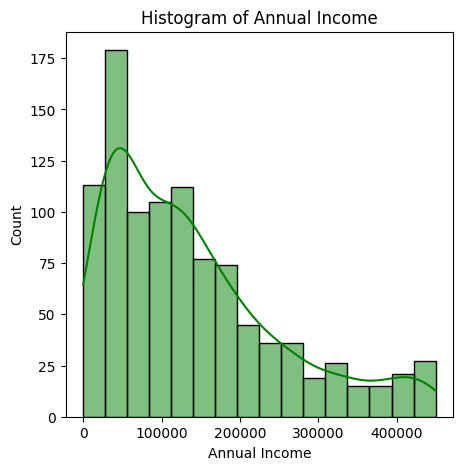

In [16]:
# Histogram of Annual Column after removing null values 
plt.figure(figsize=(5,5))
sns.histplot(df_cust["annual_income"], kde = True, color="green")
plt.title("Histogram of Annual Income")
plt.xlabel("Annual Income")
plt.show()

<h6 style="text-align:left; font-size:20px; font-weight:bold;">Handling Outliers in Customer Dataset (Annual Income)</h6>

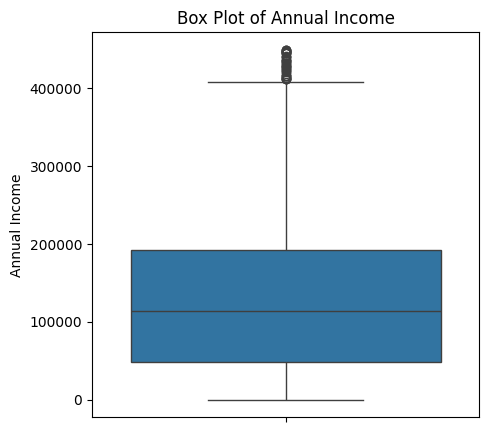

In [17]:
# Boxplot of annual income column to detect outliers
plt.figure(figsize=(5,5))
sns.boxplot(df_cust["annual_income"])
plt.title("Box Plot of Annual Income")
plt.ylabel("Annual Income")
plt.show()

In [18]:
df_cust[df_cust.annual_income<100]

,cust_id,name,gender,age,location,occupation,annual_income,marital_status
31,32,Veer Gambhir,Male,50,City,Business Owner,50.0,Married
262,263,Veer Rathod,Male,53,Suburb,Business Owner,50.0,Married
316,317,Avinash Chauhan,Male,47,City,Consultant,50.0,Married
333,334,Samaira D'Souza,Female,29,City,Data Scientist,50.0,Married
340,341,Ridhi Rastogi,Female,33,Rural,Fullstack Developer,50.0,Married
543,544,Gauri Gupta,Male,54,City,Consultant,2.0,Married
592,593,Vivaan Pande,Female,32,City,Business Owner,50.0,Married
633,634,Aradhya Pandey,Male,26,City,Data Scientist,2.0,Married
686,687,Gauri Nanda,Male,40,City,Business Owner,2.0,Married
696,697,Avani Lalwani,Male,47,City,Consultant,20.0,Married


In [19]:
df_cust[df_cust.annual_income>400000]

,cust_id,name,gender,age,location,occupation,annual_income,marital_status
21,22,Aarohi Jain,Male,59,City,Business Owner,435536.0,Married
35,36,Ridhi Taneja,Male,41,City,Business Owner,448699.0,Married
38,39,Mihika Rathod,Female,50,City,Business Owner,400804.0,Single
52,53,Aahana Khanna,Male,59,Suburb,Business Owner,446205.0,Single
60,61,Suhani Arora,Male,64,City,Business Owner,424763.0,Married
123,124,Myra Sareen,Male,63,City,Business Owner,411300.0,Married
160,161,Ritvik Tiwari,Male,47,City,Business Owner,432333.0,Married
179,180,Anaya Singhania,Male,53,City,Business Owner,412037.0,Married
230,231,Rohan Kapoor,Female,32,Suburb,Business Owner,449346.0,Married
233,234,Rishabh Rana,Male,58,City,Business Owner,448510.0,Single


In [20]:
df_cust[df_cust.annual_income>400000].shape

(44, 8)

In [21]:
# Replaced annual income with occupation wise median where annual income less than 100
for index, row in df_cust.iterrows():
    if row["annual_income"]<100:
        df_cust.at[index, "annual_income"] = occupation_wise_income_median[row["occupation"]]

In [22]:
df_cust.loc[[316,340]]

,cust_id,name,gender,age,location,occupation,annual_income,marital_status
316,317,Avinash Chauhan,Male,47,City,Consultant,58017.0,Married
340,341,Ridhi Rastogi,Female,33,Rural,Fullstack Developer,76774.0,Married


In [23]:
df_cust.describe()

,cust_id,age,annual_income
count,1000.000000,1000.000000,1000.000000
mean,500.500000,36.405000,140483.548500
std,288.819436,15.666155,110463.002934
min,1.000000,1.000000,5175.000000
25%,250.750000,26.000000,49620.500000
50%,500.500000,32.000000,115328.000000
75%,750.250000,46.000000,195514.250000
max,1000.000000,135.000000,449346.000000


In [24]:
# Calculated average occupation wise annual income to check wheather business woner may have 
# more than 400000 annual income or not. Since average income of business woner is around 270000,
# someone may have more than 400000. It is not an outlier
occupation_wise_income_mean = round(df_cust.groupby("occupation")["annual_income"].mean().sort_values(),2)
occupation_wise_income_mean

occupation
Artist                  45309.24
Consultant              60703.15
Accountant              64123.56
Freelancer              76327.51
Fullstack Developer     78727.97
Data Scientist         137021.27
Business Owner         268447.37
Name: annual_income, dtype: float64

In [25]:
occupation_wise_income_mean.index

Index(['Artist', 'Consultant', 'Accountant', 'Freelancer',
       'Fullstack Developer', 'Data Scientist', 'Business Owner'],
      dtype='str', name='occupation')

In [26]:
occupation_wise_income_mean.values

array([ 45309.24,  60703.15,  64123.56,  76327.51,  78727.97, 137021.27,
       268447.37])

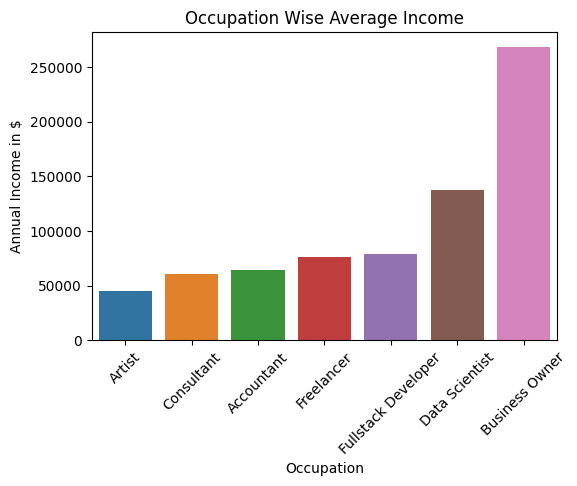

In [27]:
# Barplot of occupation average income
plt.figure(figsize=(6,4))
sns.barplot(x=occupation_wise_income_mean.index, y=occupation_wise_income_mean.values, palette="tab10")
plt.title("Occupation Wise Average Income")
plt.xlabel("Occupation")
plt.ylabel("Annual Income in $")
plt.xticks(rotation = 45)
plt.show()

In [28]:
other_cat_columns = ["gender","location","marital_status","occupation"]

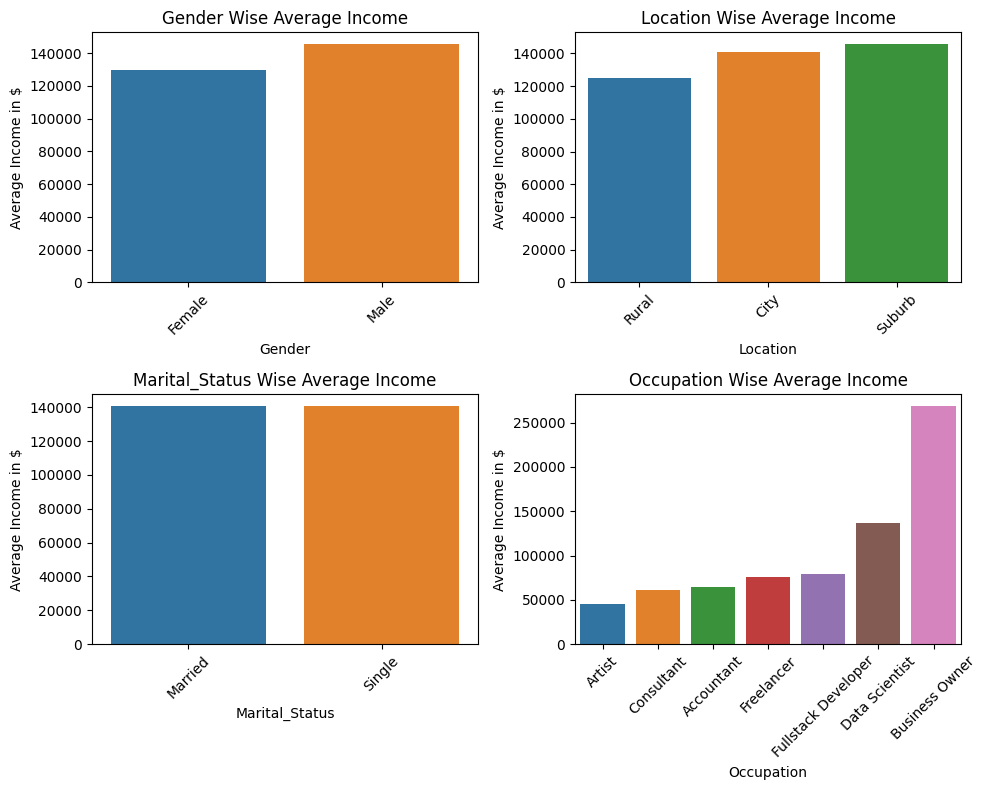

In [29]:
# Barplots of other categorical columns
n_cols = 2
n_rows = math.ceil(len(other_cat_columns) / n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(10, 4 * n_rows))
axes = axes.flatten()
for i, col in enumerate(other_cat_columns):

    average_income_per_group = round(
        df_cust.groupby(col)["annual_income"].mean().sort_values(),2
    )
    sns.barplot(
        x=average_income_per_group.index, y=average_income_per_group.values, palette="tab10", ax=axes[i]
    )
    axes[i].set_title(f"{col} wise average income".title())
    axes[i].set_xlabel(col.title())
    axes[i].set_ylabel("Average Income in $")
    axes[i].tick_params(axis='x', rotation=45)
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])
plt.tight_layout()
plt.show()

<h6 style="text-align:left; font-size:20px; font-weight:bold;">Handling Outliers in Customer Dataset (Age)</h6>

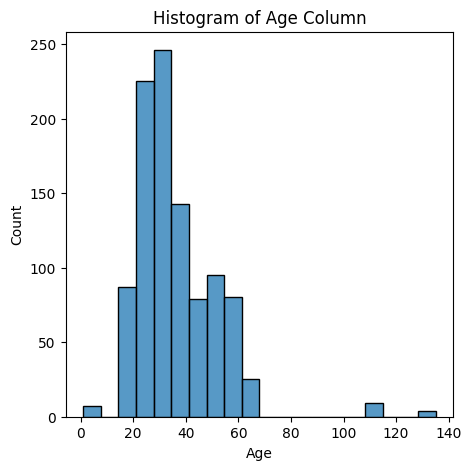

In [30]:
# Histogram og age column
plt.figure(figsize=(5,5))
sns.histplot(data=df_cust.age, bins=20)
plt.title("Histogram of Age Column")
plt.xlabel("Age")
plt.show()

In [31]:
df_cust.age.describe()

count    1000.000000
mean       36.405000
std        15.666155
min         1.000000
25%        26.000000
50%        32.000000
75%        46.000000
max       135.000000
Name: age, dtype: float64

In [32]:
# Replaced age with median age where age is less than 15 and more than 80
median_age = df_cust["age"].median()
df_cust.loc[(df_cust["age"] < 15) | (df_cust["age"] > 80),"age"] = median_age

In [33]:
df_cust.age.describe()

count    1000.000000
mean       35.506000
std        12.192072
min        18.000000
25%        26.000000
50%        32.000000
75%        44.000000
max        64.000000
Name: age, dtype: float64

In [34]:
# Assigned multiple age group
groups = [18, 29, 49, 65]
labels = ["18-30", "30-50", "50-65"]
df_cust["age_group"] = pd.cut(df_cust["age"],bins=groups,labels=labels)

In [35]:
df_cust.head()

,cust_id,name,gender,age,location,occupation,annual_income,marital_status,age_group
0,1,Dhruv Bansal,Female,32,City,Business Owner,358211.0,Married,30-50
1,2,Kabir Thakur,Female,47,City,Consultant,65172.0,Single,30-50
2,3,Kriti Mangal,Male,21,City,Freelancer,22378.0,Married,18-30
3,4,Sara Dwivedi,Male,24,Rural,Freelancer,33563.0,Married,18-30
4,5,Aarohi Negi,Male,48,City,Consultant,39406.0,Married,30-50


In [36]:
age_group_counts_pct = round(df_cust.age_group.value_counts(normalize=True)*100,2)
age_group_counts_pct

age_group
18-30    42.23
30-50    39.70
50-65    18.07
Name: proportion, dtype: float64

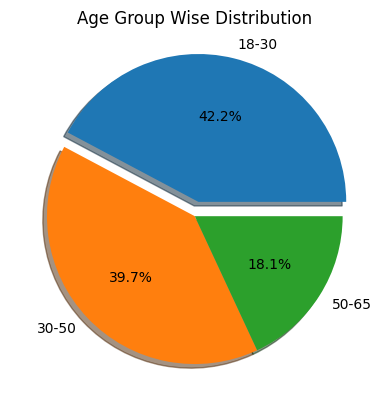

In [37]:
# Pie chart of different age group
plt.pie(age_group_counts_pct, labels=age_group_counts_pct.index, autopct='%1.1f%%', shadow=True, explode=(0.1,0,0))
plt.title("Age Group Wise Distribution")
plt.show()

In [38]:
# Location wise customer's gender distribution
customer_location_gender = df_cust.groupby(["location","gender"]).size().unstack()
customer_location_gender

gender,Female,Male
location,,
City,226,457
Rural,26,59
Suburb,74,158


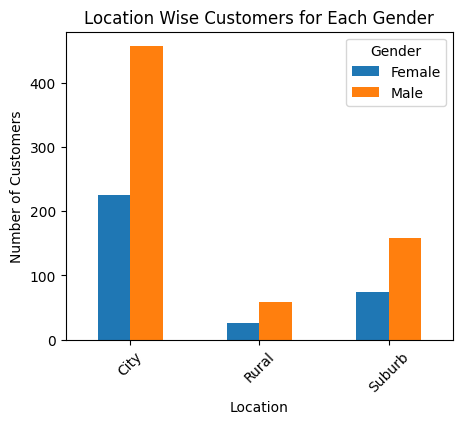

In [39]:
customer_location_gender.plot(kind= "bar", figsize = (5,4))
plt.title("Location Wise Customers for Each Gender")
plt.legend(title="Gender")
plt.xlabel("Location")
plt.ylabel("Number of Customers")
plt.xticks(rotation = 45)
plt.show()

<h6 style="text-align:left; font-size:25px; font-weight:bold;">Credit Dataset Analysis</h6>

In [40]:
df_credit.head(5)

,cust_id,credit_score,credit_utilisation,outstanding_debt,credit_inquiries_last_6_months,credit_limit
0,1,749,0.585171,19571.0,0.0,40000.0
1,2,587,0.107928,161644.0,2.0,1250.0
2,3,544,0.854807,513.0,4.0,1000.0
3,4,504,0.336938,224.0,2.0,1000.0
4,5,708,0.586151,18090.0,2.0,40000.0


In [41]:
df_credit.isnull().sum()

cust_id                            0
credit_score                       0
credit_utilisation                 4
outstanding_debt                   4
credit_inquiries_last_6_months     4
credit_limit                      69
dtype: int64

In [42]:
df_credit.cust_id.nunique()

1000

In [43]:
df_credit[df_credit["cust_id"].duplicated(keep = False)]

,cust_id,credit_score,credit_utilisation,outstanding_debt,credit_inquiries_last_6_months,credit_limit
516,517,308,NaN,NaN,NaN,NaN
517,517,308,0.113860,33.0,3.0,500.0
569,569,344,NaN,NaN,NaN,NaN
570,569,344,0.112599,37.0,0.0,500.0
607,606,734,NaN,NaN,NaN,NaN
608,606,734,0.193418,4392.0,1.0,40000.0
664,662,442,NaN,NaN,NaN,NaN
665,662,442,0.856039,266.0,2.0,500.0


In [44]:
# Removed duplicate records from credit dataset
df_credit = df_credit.drop_duplicates(subset = ["cust_id"], keep = "last")
df_credit.shape

(1000, 6)

In [45]:
df_credit.describe()

,cust_id,credit_score,credit_utilisation,outstanding_debt,credit_inquiries_last_6_months,credit_limit
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,935.000000
mean,500.500000,589.182000,0.498950,9683.597000,1.955000,19235.561497
std,288.819436,152.284929,0.233139,25255.893671,1.414559,24489.997195
min,1.000000,300.000000,0.103761,33.000000,0.000000,500.000000
25%,250.750000,460.000000,0.293917,221.000000,1.000000,750.000000
50%,500.500000,601.500000,0.487422,550.000000,2.000000,1250.000000
75%,750.250000,738.000000,0.697829,11819.500000,3.000000,40000.000000
max,1000.000000,799.000000,0.899648,209901.000000,4.000000,60000.000000


In [46]:
# Checking null values in credit dataset
df_credit.isnull().sum()

cust_id                            0
credit_score                       0
credit_utilisation                 0
outstanding_debt                   0
credit_inquiries_last_6_months     0
credit_limit                      65
dtype: int64

In [47]:
df_credit.shape

(1000, 6)

In [48]:
df_credit[df_credit.credit_limit.isnull()]

,cust_id,credit_score,credit_utilisation,outstanding_debt,credit_inquiries_last_6_months,credit_limit
10,11,679,0.557450,9187.0,2.0,NaN
35,36,790,0.112535,4261.0,1.0,NaN
37,38,514,0.296971,238.0,2.0,NaN
45,46,761,0.596041,24234.0,2.0,NaN
64,65,734,0.473715,13631.0,0.0,NaN
...,...,...,...,...,...,...
912,909,479,0.487555,320.0,3.0,NaN
931,928,311,0.832244,316.0,2.0,NaN
948,945,526,0.272734,227.0,1.0,NaN
954,951,513,0.175914,131.0,3.0,NaN


In [49]:
df_credit.credit_limit.value_counts()

credit_limit
500.0      229
60000.0    186
40000.0    137
1500.0     100
1000.0      90
750.0       76
1250.0      75
20000.0     42
Name: count, dtype: int64

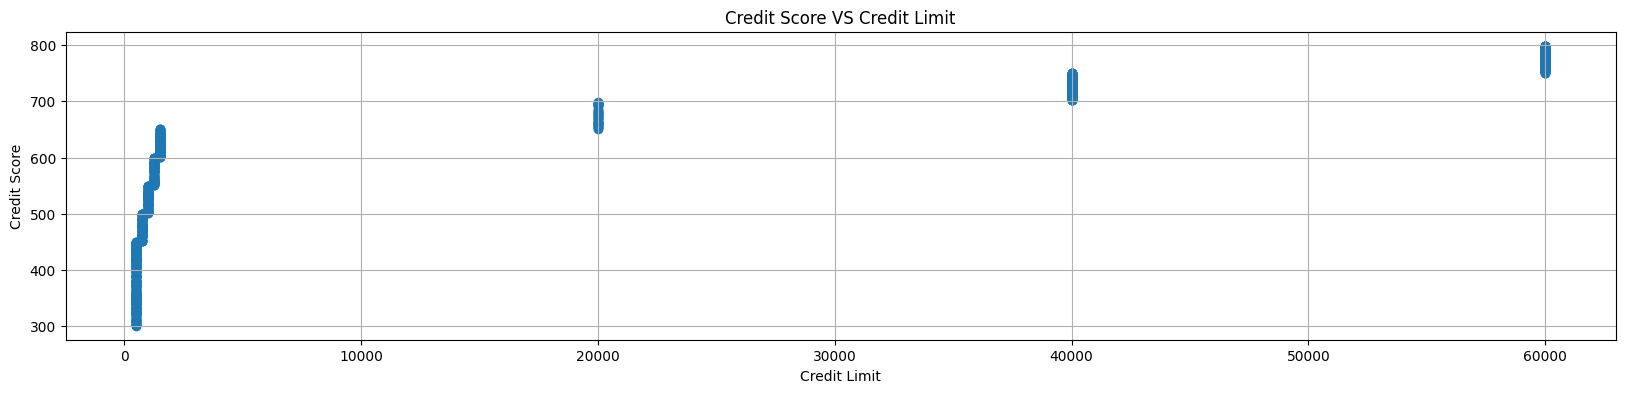

In [50]:
# Scatter plot of credit limit and credit score
plt.figure(figsize = (20,4))
plt.scatter(df_credit.credit_limit, df_credit.credit_score)
plt.title("Credit Score VS Credit Limit")
plt.grid(visible = True)
plt.xlabel("Credit Limit")
plt.ylabel("Credit Score")
plt.show()

In [51]:
# Created different credit score groups
bins = [300, 450, 500, 550, 600, 650, 700, 750, 800]
labels = [f"{start}-{end-1}" for start, end in zip(bins, bins[1:])]
df_credit["credit_score_group"] = pd.cut(df_credit["credit_score"], 
                                         bins=bins, labels=labels, 
                                         include_lowest= True, right=False)

In [52]:
# Assigned most frequent credit limts to different credit score groups
df_mode = df_credit.groupby("credit_score_group")["credit_limit"].agg(lambda x: x.mode().iloc[0]).reset_index()
df_mode

,credit_score_group,credit_limit
0,300-449,500.0
1,450-499,750.0
2,500-549,1000.0
3,550-599,1250.0
4,600-649,1500.0
5,650-699,20000.0
6,700-749,40000.0
7,750-799,60000.0


In [53]:
df_credit = pd.merge(df_credit, df_mode, how="right", on = "credit_score_group", suffixes=("","_mode"))

In [54]:
df_credit[df_credit.credit_limit.isnull()].head(5)

,cust_id,credit_score,credit_utilisation,outstanding_debt,credit_inquiries_last_6_months,credit_limit,credit_score_group,credit_limit_mode
21,73,323,0.858835,216.0,1.0,NaN,300-449,500.0
49,212,337,0.608700,226.0,4.0,NaN,300-449,500.0
64,259,427,0.339428,136.0,4.0,NaN,300-449,500.0
76,307,304,0.254547,74.0,4.0,NaN,300-449,500.0
98,401,420,0.319390,139.0,0.0,NaN,300-449,500.0


In [55]:
df_credit["credit_limit"] = df_credit["credit_limit"].fillna(df_credit["credit_limit_mode"])
df_credit.drop(columns = "credit_limit_mode", inplace = True)

In [56]:
df_credit.isnull().sum()

cust_id                           0
credit_score                      0
credit_utilisation                0
outstanding_debt                  0
credit_inquiries_last_6_months    0
credit_limit                      0
credit_score_group                0
dtype: int64

In [57]:
df_credit.shape

(1000, 7)

In [58]:
df_credit.describe()

,cust_id,credit_score,credit_utilisation,outstanding_debt,credit_inquiries_last_6_months,credit_limit
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.00000
mean,500.500000,589.182000,0.498950,9683.597000,1.955000,19733.75000
std,288.819436,152.284929,0.233139,25255.893671,1.414559,24717.43818
min,1.000000,300.000000,0.103761,33.000000,0.000000,500.00000
25%,250.750000,460.000000,0.293917,221.000000,1.000000,750.00000
50%,500.500000,601.500000,0.487422,550.000000,2.000000,1500.00000
75%,750.250000,738.000000,0.697829,11819.500000,3.000000,40000.00000
max,1000.000000,799.000000,0.899648,209901.000000,4.000000,60000.00000


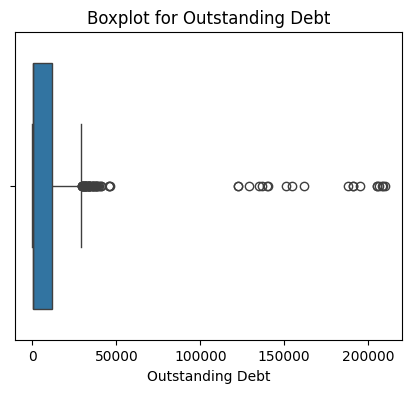

In [59]:
# Boxplot of outstanding debt column to detect outliers
plt.figure(figsize=(5,4))
sns.boxplot(x = df_credit["outstanding_debt"])
plt.title("Boxplot for Outstanding Debt")
plt.xlabel("Outstanding Debt")
plt.show()

In [60]:
# Checking outstanding debt more than 60000. Because outstanding debt can't have more than maximum credit limit
df_credit[df_credit.outstanding_debt>60000].head(5)

,cust_id,credit_score,credit_utilisation,outstanding_debt,credit_inquiries_last_6_months,credit_limit,credit_score_group
46,205,303,0.364360,187849.0,0.0,500.0,300-449
89,351,320,0.285081,150860.0,0.0,500.0,300-449
157,637,420,0.323984,140063.0,4.0,500.0,300-449
287,647,498,0.658087,128818.0,3.0,750.0,450-499
292,724,465,0.658173,140008.0,3.0,750.0,450-499


In [61]:
df_credit[df_credit.outstanding_debt>60000].shape

(20, 7)

In [62]:
# Assigned credit limit to their outstanding debt where outstanding debt is more than credit limit 
# assuming that they have utilized maximum credit limit
df_credit.loc[df_credit.outstanding_debt>df_credit.credit_limit, "outstanding_debt"] = df_credit["credit_limit"]

In [63]:
df_credit[df_credit.outstanding_debt>60000]

,cust_id,credit_score,credit_utilisation,outstanding_debt,credit_inquiries_last_6_months,credit_limit,credit_score_group


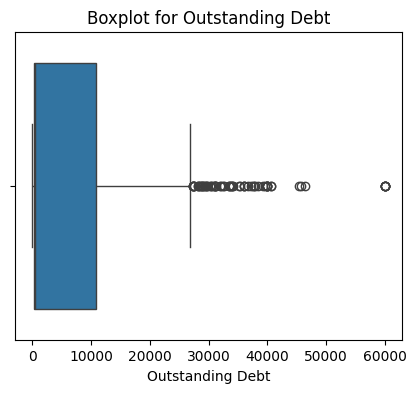

In [64]:
plt.figure(figsize=(5,4))
sns.boxplot(x = df_credit["outstanding_debt"])
plt.title("Boxplot for Outstanding Debt")
plt.xlabel("Outstanding Debt")
plt.show()

In [65]:
df_credit.loc[[46,287]]

,cust_id,credit_score,credit_utilisation,outstanding_debt,credit_inquiries_last_6_months,credit_limit,credit_score_group
46,205,303,0.364360,500.0,0.0,500.0,300-449
287,647,498,0.658087,750.0,3.0,750.0,450-499


In [66]:
df_cust.head(5)

,cust_id,name,gender,age,location,occupation,annual_income,marital_status,age_group
0,1,Dhruv Bansal,Female,32,City,Business Owner,358211.0,Married,30-50
1,2,Kabir Thakur,Female,47,City,Consultant,65172.0,Single,30-50
2,3,Kriti Mangal,Male,21,City,Freelancer,22378.0,Married,18-30
3,4,Sara Dwivedi,Male,24,Rural,Freelancer,33563.0,Married,18-30
4,5,Aarohi Negi,Male,48,City,Consultant,39406.0,Married,30-50


In [67]:
df_credit.head(5)

,cust_id,credit_score,credit_utilisation,outstanding_debt,credit_inquiries_last_6_months,credit_limit,credit_score_group
0,6,442,0.705409,246.0,4.0,500.0,300-449
1,12,429,0.627645,263.0,0.0,500.0,300-449
2,16,347,0.531660,190.0,0.0,500.0,300-449
3,19,447,0.795650,292.0,1.0,500.0,300-449
4,21,381,0.714710,307.0,0.0,500.0,300-449


In [68]:
# Merged customer and credit dataset
df_cust_credit = pd.merge(left= df_cust, right= df_credit, how= "inner", on= "cust_id")
df_cust_credit.head(5)

,cust_id,name,gender,age,location,occupation,annual_income,marital_status,age_group,credit_score,credit_utilisation,outstanding_debt,credit_inquiries_last_6_months,credit_limit,credit_score_group
0,1,Dhruv Bansal,Female,32,City,Business Owner,358211.0,Married,30-50,749,0.585171,19571.0,0.0,40000.0,700-749
1,2,Kabir Thakur,Female,47,City,Consultant,65172.0,Single,30-50,587,0.107928,1250.0,2.0,1250.0,550-599
2,3,Kriti Mangal,Male,21,City,Freelancer,22378.0,Married,18-30,544,0.854807,513.0,4.0,1000.0,500-549
3,4,Sara Dwivedi,Male,24,Rural,Freelancer,33563.0,Married,18-30,504,0.336938,224.0,2.0,1000.0,500-549
4,5,Aarohi Negi,Male,48,City,Consultant,39406.0,Married,30-50,708,0.586151,18090.0,2.0,40000.0,700-749


In [69]:
df_cust_credit.shape

(1000, 15)

In [70]:
# Calculated correlation matrix for each numerical columns
num_cols = ["credit_score", "credit_limit", "credit_utilisation", "outstanding_debt", "annual_income", "age"]
corr_matrix = df_cust_credit[num_cols].corr()

In [71]:
corr_matrix

,credit_score,credit_limit,credit_utilisation,outstanding_debt,annual_income,age
credit_score,1.000000,0.847952,-0.070445,0.680654,0.575751,0.439237
credit_limit,0.847952,1.000000,-0.080493,0.810581,0.684775,0.504766
credit_utilisation,-0.070445,-0.080493,1.000000,0.192838,-0.086368,-0.017185
outstanding_debt,0.680654,0.810581,0.192838,1.000000,0.555661,0.444198
annual_income,0.575751,0.684775,-0.086368,0.555661,1.000000,0.611092
age,0.439237,0.504766,-0.017185,0.444198,0.611092,1.000000


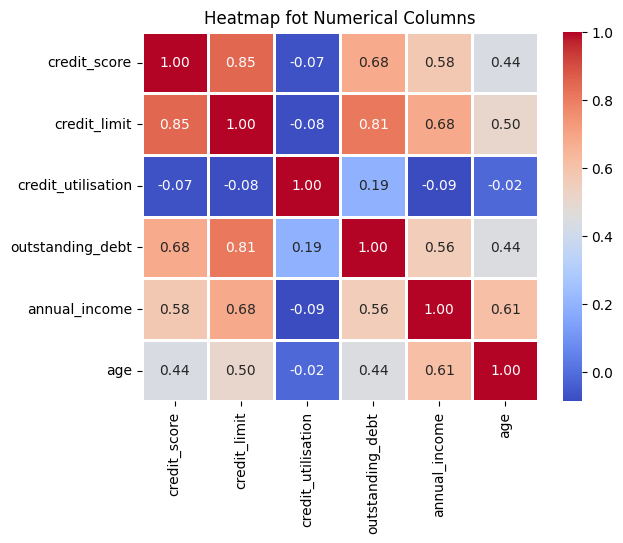

In [72]:
sns.heatmap(corr_matrix, annot= True, cmap="coolwarm", linewidths=0.9, fmt=".2f")
plt.title("Heatmap fot Numerical Columns")
plt.show()

<h6 style="text-align:left; font-size:25px; font-weight:bold;">Transaction Dataset Analysis</h6>

In [73]:
df_trans.head(5)

,tran_id,cust_id,tran_date,tran_amount,platform,product_category,payment_type
0,1,705,2023-01-01,63,Flipkart,Electronics,Phonepe
1,2,385,2023-01-01,99,Alibaba,Fashion & Apparel,Credit Card
2,3,924,2023-01-01,471,Shopify,Sports,Phonepe
3,4,797,2023-01-01,33,Shopify,Fashion & Apparel,Gpay
4,5,482,2023-01-01,68,Amazon,Fashion & Apparel,Net Banking


In [74]:
df_trans.shape

(500000, 7)

In [75]:
df_trans.isnull().sum()

tran_id                0
cust_id                0
tran_date              0
tran_amount            0
platform            4941
product_category       0
payment_type           0
dtype: int64

In [76]:
df_trans.platform.mode()

0    Amazon
Name: platform, dtype: str

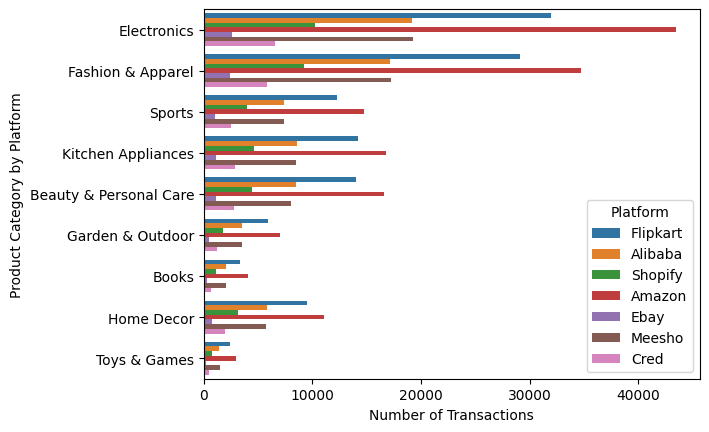

In [77]:
sns.countplot(y= "product_category", hue= "platform", data= df_trans)
plt.xlabel("Number of Transactions")
plt.ylabel("Product Category by Platform")
plt.legend(title= "Platform")
plt.show()

In [78]:
df_trans["platform"] = df_trans["platform"].fillna(df_trans["platform"].mode()[0])

In [79]:
df_trans.isnull().sum()

tran_id             0
cust_id             0
tran_date           0
tran_amount         0
platform            0
product_category    0
payment_type        0
dtype: int64

In [80]:
df_trans.platform.unique()

<StringArray>
['Flipkart', 'Alibaba', 'Shopify', 'Amazon', 'Ebay', 'Meesho', 'Cred']
Length: 7, dtype: str

In [81]:
df_trans["tran_amount"].describe()

count    500000.00000
mean       3225.20733
std       13098.74276
min           0.00000
25%          64.00000
50%         141.00000
75%         397.00000
max       69999.00000
Name: tran_amount, dtype: float64

In [82]:
df_trans_zero = df_trans[df_trans["tran_amount"]==0]
df_trans_zero.head(5)

,tran_id,cust_id,tran_date,tran_amount,platform,product_category,payment_type
120,121,440,2023-01-01,0,Amazon,Electronics,Credit Card
141,142,839,2023-01-01,0,Amazon,Electronics,Credit Card
517,518,147,2023-01-01,0,Amazon,Electronics,Credit Card
533,534,891,2023-01-01,0,Amazon,Electronics,Credit Card
586,587,108,2023-01-01,0,Amazon,Electronics,Credit Card


In [83]:
df_trans_zero[["platform", "product_category", "payment_type"]].value_counts()

platform  product_category  payment_type
Amazon    Electronics       Credit Card     4734
Name: count, dtype: int64

In [84]:
df_trans.head(5)

,tran_id,cust_id,tran_date,tran_amount,platform,product_category,payment_type
0,1,705,2023-01-01,63,Flipkart,Electronics,Phonepe
1,2,385,2023-01-01,99,Alibaba,Fashion & Apparel,Credit Card
2,3,924,2023-01-01,471,Shopify,Sports,Phonepe
3,4,797,2023-01-01,33,Shopify,Fashion & Apparel,Gpay
4,5,482,2023-01-01,68,Amazon,Fashion & Apparel,Net Banking


In [85]:
df_trans_temp = df_trans[(df_trans["platform"]=="Amazon") & 
    (df_trans["product_category"]=="Electronics") & 
    (df_trans["payment_type"]=="Credit Card")]
df_trans_temp.head()

,tran_id,cust_id,tran_date,tran_amount,platform,product_category,payment_type
109,110,887,2023-01-01,635,Amazon,Electronics,Credit Card
120,121,440,2023-01-01,0,Amazon,Electronics,Credit Card
141,142,839,2023-01-01,0,Amazon,Electronics,Credit Card
173,174,676,2023-01-01,60439,Amazon,Electronics,Credit Card
190,191,763,2023-01-01,697,Amazon,Electronics,Credit Card


In [86]:
df_trans_temp.shape

(15637, 7)

In [87]:
df_trans_temp[df_trans_temp.tran_amount>0]

,tran_id,cust_id,tran_date,tran_amount,platform,product_category,payment_type
109,110,887,2023-01-01,635,Amazon,Electronics,Credit Card
173,174,676,2023-01-01,60439,Amazon,Electronics,Credit Card
190,191,763,2023-01-01,697,Amazon,Electronics,Credit Card
263,264,528,2023-01-01,421,Amazon,Electronics,Credit Card
311,312,936,2023-01-01,537,Amazon,Electronics,Credit Card
...,...,...,...,...,...,...,...
499766,499767,723,2023-09-05,909,Amazon,Electronics,Credit Card
499793,499794,586,2023-09-05,304,Amazon,Electronics,Credit Card
499812,499813,688,2023-09-05,425,Amazon,Electronics,Credit Card
499860,499861,373,2023-09-05,480,Amazon,Electronics,Credit Card


In [88]:
median_to_replace = df_trans_temp[df_trans_temp.tran_amount>0].tran_amount.median()
median_to_replace

np.float64(554.0)

In [89]:
df_trans["tran_amount"] = df_trans["tran_amount"].replace(0,median_to_replace, inplace = True)

In [90]:
df_trans.describe()

,tran_id,cust_id,tran_amount
count,500000.000000,500000.000000,500000.000000
mean,250000.500000,501.400428,3230.452602
std,144337.711635,288.641924,13097.561071
min,1.000000,1.000000,2.000000
25%,125000.750000,252.000000,66.000000
50%,250000.500000,502.000000,146.000000
75%,375000.250000,752.000000,413.000000
max,500000.000000,1000.000000,69999.000000


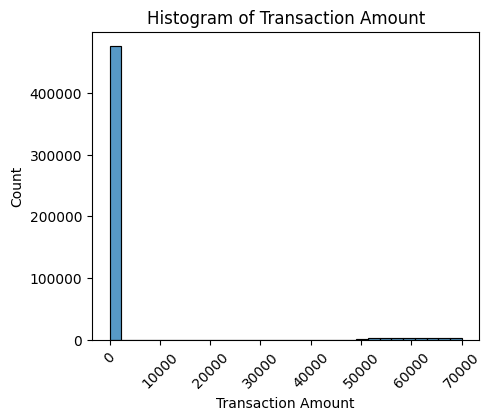

In [91]:
plt.figure(figsize=(5,4))
sns.histplot(df_trans["tran_amount"], bins= 30)
plt.title("Histogram of Transaction Amount")
plt.xlabel("Transaction Amount")
plt.xticks(rotation= 45)
plt.show()

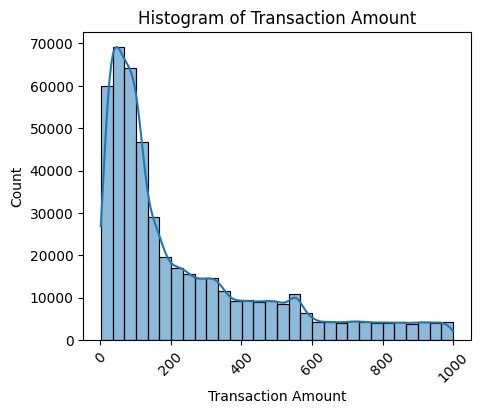

In [92]:
plt.figure(figsize=(5,4))
sns.histplot(df_trans[df_trans["tran_amount"]<10000].tran_amount, kde= True, bins= 30)
plt.title("Histogram of Transaction Amount")
plt.xlabel("Transaction Amount")
plt.xticks(rotation= 45)
plt.show()

In [93]:
Q1, Q3 = df_trans["tran_amount"].quantile([0.25,0.75])
Q1, Q3

(66.0, 413.0)

In [94]:
IQR = Q3-Q1
IQR

347.0

In [95]:
lower = Q1 - 2*IQR
upper = Q3 + 2*IQR
lower, upper

(-628.0, 1107.0)

In [96]:
df_trans_outlier = df_trans[df_trans.tran_amount>=upper]
df_trans_outlier.shape

(25000, 7)

In [97]:
df_trans_normal = df_trans[df_trans.tran_amount < upper]
df_trans_normal.head(5)

,tran_id,cust_id,tran_date,tran_amount,platform,product_category,payment_type
0,1,705,2023-01-01,63,Flipkart,Electronics,Phonepe
1,2,385,2023-01-01,99,Alibaba,Fashion & Apparel,Credit Card
2,3,924,2023-01-01,471,Shopify,Sports,Phonepe
3,4,797,2023-01-01,33,Shopify,Fashion & Apparel,Gpay
4,5,482,2023-01-01,68,Amazon,Fashion & Apparel,Net Banking


In [98]:
product_trans_mean = (df_trans_normal.groupby("product_category")["tran_amount"].mean())
product_trans_mean

product_category
Beauty & Personal Care     92.167205
Books                      29.553515
Electronics               510.172685
Fashion & Apparel          64.553463
Garden & Outdoor          125.630277
Home Decor                302.487561
Kitchen Appliances        176.773288
Sports                    269.181631
Toys & Games               50.333298
Name: tran_amount, dtype: float64

In [99]:
df_trans["tran_amount"] = df_trans["tran_amount"].astype(float)

In [100]:
for index, row in df_trans.iterrows():
    if row["tran_amount"]>upper:
        df_trans.at[index, "tran_amount"] = product_trans_mean[row["product_category"]]        

In [101]:
df_trans[df_trans["tran_amount"]>upper].shape

(0, 7)

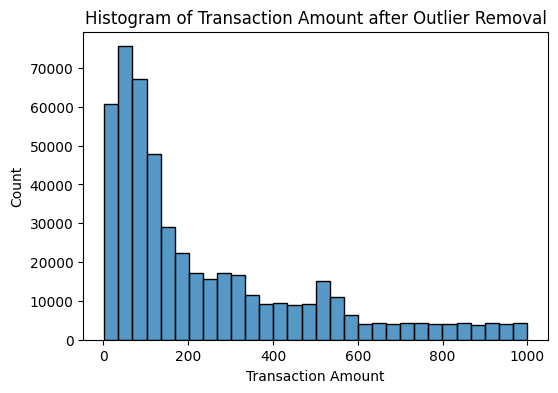

In [102]:
plt.figure(figsize=(6,4))
sns.histplot(df_trans["tran_amount"], bins= 30)
plt.title("Histogram of Transaction Amount after Outlier Removal")
plt.xlabel("Transaction Amount")
plt.show()

In [103]:
df_cust_credit_trans = pd.merge(df_cust_credit, df_trans, on= "cust_id", how= "inner")
df_cust_credit_trans.shape

(500000, 21)

In [104]:
df_cust_credit_trans.isnull().sum()

cust_id                              0
name                                 0
gender                               0
age                                  0
location                             0
occupation                           0
annual_income                        0
marital_status                       0
age_group                         7463
credit_score                         0
credit_utilisation                   0
outstanding_debt                     0
credit_inquiries_last_6_months       0
credit_limit                         0
credit_score_group                   0
tran_id                              0
tran_date                            0
tran_amount                          0
platform                             0
product_category                     0
payment_type                         0
dtype: int64

In [105]:
df_cust_credit.isnull().sum()

cust_id                            0
name                               0
gender                             0
age                                0
location                           0
occupation                         0
annual_income                      0
marital_status                     0
age_group                         15
credit_score                       0
credit_utilisation                 0
outstanding_debt                   0
credit_inquiries_last_6_months     0
credit_limit                       0
credit_score_group                 0
dtype: int64

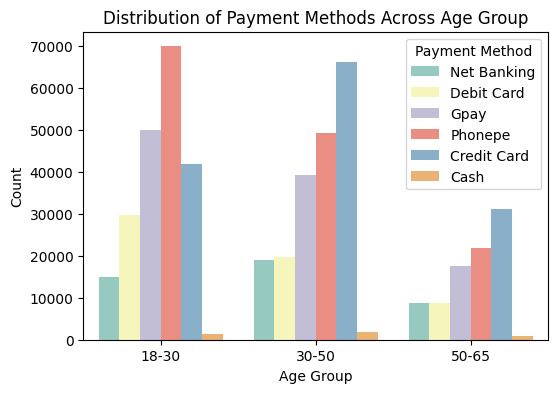

In [106]:
plt.figure(figsize=(6,4))
sns.countplot(x= "age_group", hue= "payment_type", data= df_cust_credit_trans, palette="Set3")
plt.title("Distribution of Payment Methods Across Age Group")
plt.xlabel("Age Group")
plt.ylabel("Count")
plt.legend(title= "Payment Method")
plt.show()

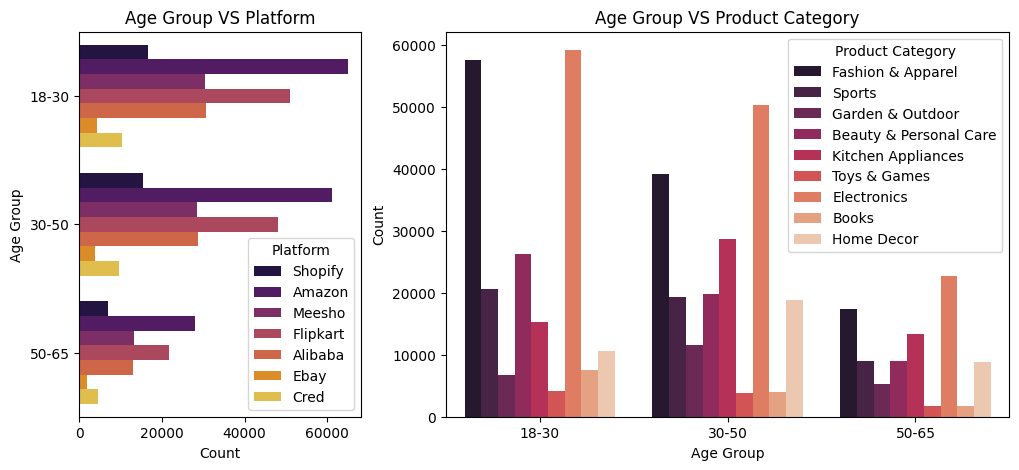

In [107]:
fig, (axis1, axis2) = plt.subplots(1, 2, figsize= (12,5), gridspec_kw= {"width_ratios":[1,2]})
sns.countplot(y= "age_group", hue= "platform", data= df_cust_credit_trans, ax= axis1, palette="inferno")
axis1.set_title("Age Group VS Platform")
axis1.set_xlabel("Count")
axis1.set_ylabel("Age Group")
axis1.legend(title= "Platform")

sns.countplot(x= "age_group", hue= "product_category", data= df_cust_credit_trans, ax= axis2, palette="rocket")
axis2.set_title("Age Group VS Product Category")
axis2.set_xlabel("Age Group")
axis2.set_ylabel("Count")
axis2.legend(title= "Product Category")

plt.show()

In [108]:
age_group_matrix = df_cust_credit.groupby("age_group")[["annual_income", 
                                                        "credit_score", 
                                                        "credit_limit"]].mean().reset_index()
age_group_matrix

,age_group,annual_income,credit_score,credit_limit
0,18-30,80045.060096,528.346154,8662.259615
1,30-50,154653.067775,604.304348,21945.012788
2,50-65,259346.870787,705.544944,42331.460674


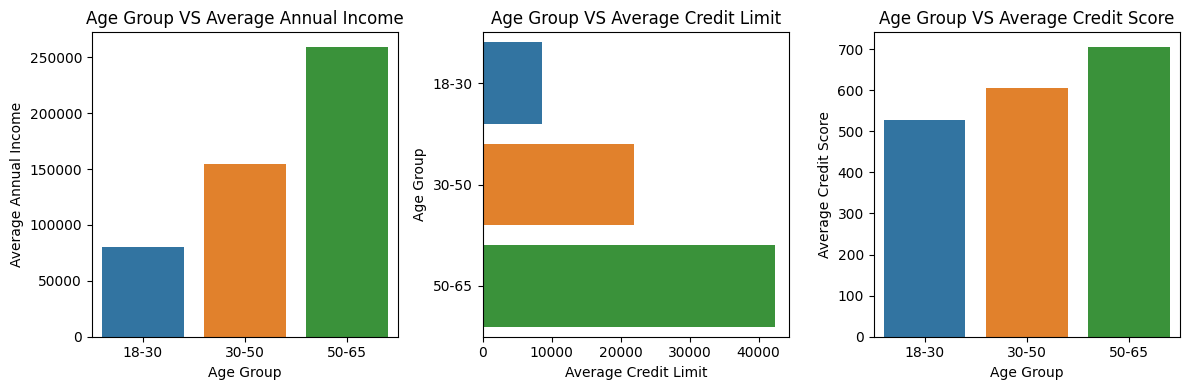

In [109]:
fig, (axis1, axis2, axis3) = plt.subplots(1,3, figsize = (12,4))

sns.barplot(data= age_group_matrix, x= "age_group", y= "annual_income", ax= axis1, palette="tab10")
axis1.set_title("Age Group VS Average Annual Income")
axis1.set_xlabel("Age Group")
axis1.set_ylabel("Average Annual Income")

sns.barplot(data= age_group_matrix, x= "credit_limit", y= "age_group", ax= axis2, palette="tab10")
axis2.set_title("Age Group VS Average Credit Limit")
axis2.set_xlabel("Average Credit Limit")
axis2.set_ylabel("Age Group")

sns.barplot(data= age_group_matrix, x= "age_group", y= "credit_score", ax= axis3, palette="tab10")
axis3.set_title("Age Group VS Average Credit Score")
axis3.set_xlabel("Age Group")
axis3.set_ylabel("Average Credit Score")

plt.tight_layout()
plt.show()